# Lesson 02 - From sound to spectrogram

A CNN is built for images. To use one on sound, we turn each 5-second clip into a picture of
**which frequencies are loud, at which moment**: a spectrogram. This lesson builds that picture
step by step, using exactly the code that made `data/mel.npy` (`src/features.py`).

Steps: waveform -> FFT -> STFT (spectrogram) -> mel bands -> decibels.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

import matplotlib.pyplot as plt
import numpy as np
import torch
import data as D
import features as F
from paths import AUDIO_ZIP, DATA_DIR

mel, table = D.open_features(DATA_DIR)
row = int(table.index[(table.label == "cargo") & (table.mean_distance < 600)][0])

if AUDIO_ZIP.exists():
    from shipzip import SplitZip
    wave, sr, _ = F.decode_wav(SplitZip(str(AUDIO_ZIP)).read(table.zip_name.iat[row]))
    source = f"real clip {row} ({table.label.iat[row]}, {table.mean_distance.iat[row]:.0f} m)"
else:
    # no audio on this machine: a ship-like test signal (engine tone at 60 Hz with harmonics + ocean noise)
    sr = F.SR
    t = np.arange(F.CLIP_SAMPLES) / sr
    wave = sum(0.02 / k * np.sin(2 * np.pi * 60 * k * t) for k in range(1, 6))
    wave = (wave + 0.005 * np.random.default_rng(0).normal(size=t.size)).astype(np.float32)
    source = "synthetic ship-like signal (audio zip not found)"
print(source, "|", len(wave), "samples at", sr, "Hz =", len(wave) / sr, "seconds")

real clip 21607 (cargo, 163 m) | 160000 samples at 32000 Hz = 5.0 seconds


## 1. The waveform

The hydrophone measures pressure 32,000 times per second. That's 160,000 numbers per clip.
Plotted directly, it shows loudness changing over time, but not *which* sounds are present.

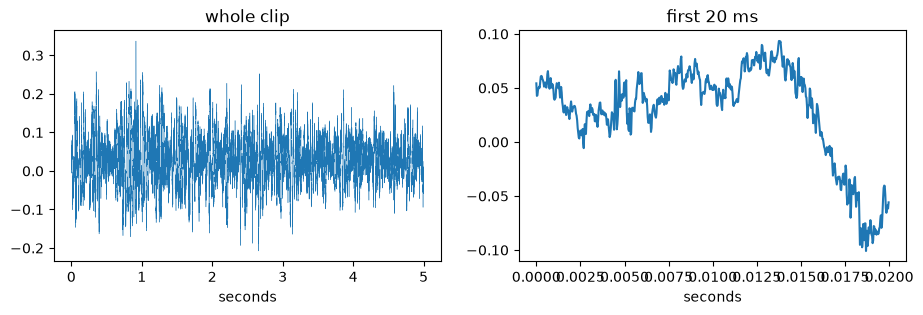

In [2]:
t = np.arange(len(wave)) / sr
fig, ax = plt.subplots(1, 2, figsize=(11, 3))
ax[0].plot(t, wave, lw=0.3); ax[0].set_title("whole clip"); ax[0].set_xlabel("seconds")
ax[1].plot(t[:640], wave[:640]); ax[1].set_title("first 20 ms"); ax[1].set_xlabel("seconds")
plt.show()

## 2. The FFT: which frequencies are in the clip?

The **Fast Fourier Transform** splits a signal into sine waves and tells how strong each frequency is.
Ships produce **tonals** (sharp peaks) from engines and propellers, mostly below 1 kHz, on top of broadband noise.

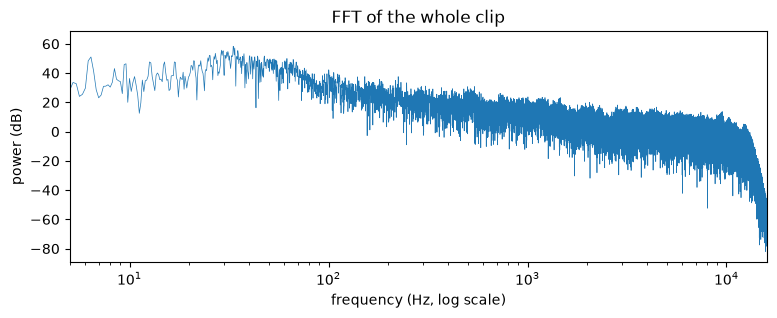

In [3]:
spectrum = np.abs(np.fft.rfft(wave * np.hanning(len(wave)))) ** 2
freqs = np.fft.rfftfreq(len(wave), 1 / sr)
plt.figure(figsize=(9, 3))
plt.semilogx(freqs[1:], 10 * np.log10(spectrum[1:] + 1e-20), lw=0.5)
plt.xlabel("frequency (Hz, log scale)"); plt.ylabel("power (dB)"); plt.xlim(5, sr / 2)
plt.title("FFT of the whole clip"); plt.show()

## 3. STFT: an FFT for every moment = a spectrogram

One FFT for 5 seconds loses all timing. The **Short-Time Fourier Transform** cuts the clip into short
overlapping windows and takes an FFT of each:

- window `N_FFT = 4096` samples = 128 ms, which gives 7.8 Hz frequency resolution (fine detail for low tonals),
- moved by `HOP = 320` samples = 10 ms each step, which gives 501 time steps.

The trade-off: a longer window means sharper frequencies but blurrier timing.

STFT shape (frequency bins x time steps): (2049, 501)


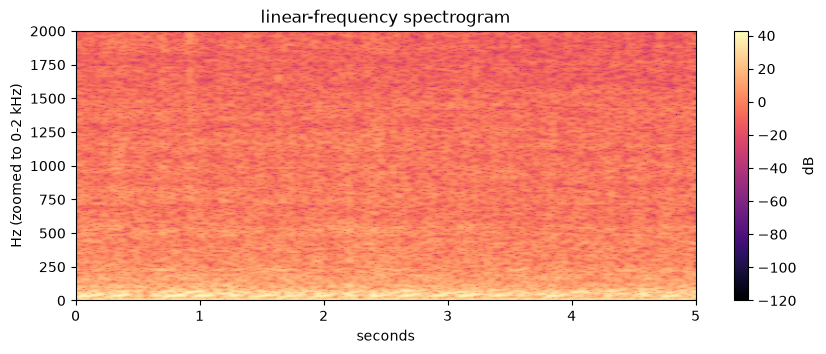

In [4]:
w = torch.from_numpy(F.fix_length(F.resample(wave, sr)))
spec = torch.stft(w, F.N_FFT, F.HOP, window=torch.hann_window(F.N_FFT), return_complex=True)
power = spec.abs() ** 2
print("STFT shape (frequency bins x time steps):", tuple(power.shape))
plt.figure(figsize=(10, 3.5))
plt.imshow(10 * torch.log10(power + 1e-12), origin="lower", aspect="auto", cmap="magma",
           extent=[0, 5, 0, sr / 2])
plt.ylim(0, 2000); plt.colorbar(label="dB")
plt.xlabel("seconds"); plt.ylabel("Hz (zoomed to 0-2 kHz)"); plt.title("linear-frequency spectrogram")
plt.show()

## 4. Mel bands: more detail where it matters

2,049 frequency bins is a lot, and most of them sit at high frequencies where ships are less distinctive.
The **mel scale** spaces bands narrowly at low frequencies and widely at high ones (it was designed around
human hearing, and it suits ship noise too):

$$ \text{mel}(f) = 2595 \log_{10}(1 + f/700) $$

Each of the 128 triangular filters below adds up the FFT bins under it.

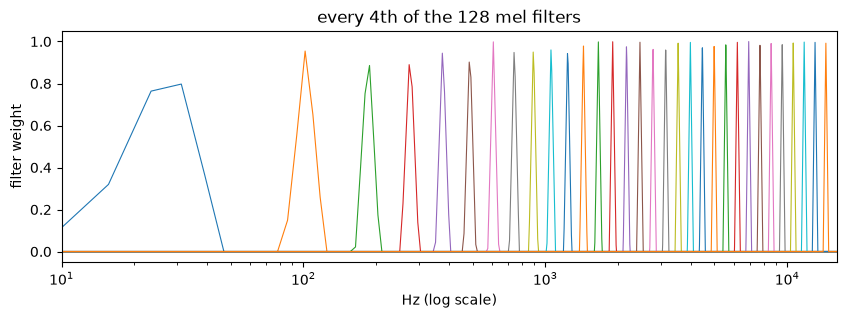

filter centre frequencies (Hz), first 5: [ 27.6  45.6  64.1  83.  102.4]


In [5]:
fb = F.mel_filterbank()
fft_freqs = np.linspace(0, sr / 2, fb.shape[1])
plt.figure(figsize=(10, 3))
for m in range(0, 128, 4):
    plt.plot(fft_freqs, fb[m], lw=0.8)
plt.xscale("log"); plt.xlim(10, sr / 2); plt.xlabel("Hz (log scale)"); plt.ylabel("filter weight")
plt.title("every 4th of the 128 mel filters"); plt.show()
print("filter centre frequencies (Hz), first 5:", F.mel_to_hz(np.linspace(F.hz_to_mel(F.FMIN), F.hz_to_mel(F.FMAX), 130)[1:6]).round(1))

## 5. Decibels, and the finished picture

Power values span a huge range, so we take `10 * log10(power)`: decibels. Each step of +10 dB means
10x more power. `LogMel` does steps 3-5 in one go. The result should match what is stored in `mel.npy`.

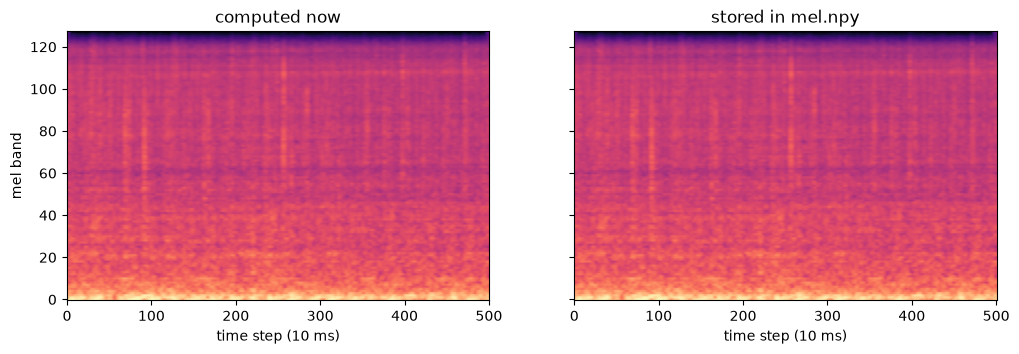

largest difference (dB): 0.016834259033203125


In [6]:
logmel = F.LogMel()(w.unsqueeze(0))[0].numpy()
fig, ax = plt.subplots(1, 2, figsize=(12, 3.5), sharey=True)
ax[0].imshow(logmel, origin="lower", aspect="auto", cmap="magma"); ax[0].set_title("computed now")
ax[1].imshow(mel[row].astype(np.float32), origin="lower", aspect="auto", cmap="magma"); ax[1].set_title("stored in mel.npy")
ax[0].set_ylabel("mel band"); [a.set_xlabel("time step (10 ms)") for a in ax]
plt.show()
if AUDIO_ZIP.exists():
    print("largest difference (dB):", float(np.abs(logmel - mel[row].astype(np.float32)).max()))

## 6. Why we keep the true loudness

Many image pipelines rescale every picture to the same brightness. We deliberately **don't**, because loudness
carries distance information. Normalisation happens once, with the *same* per-band mean and standard
deviation for every clip (computed from training clips only).

But look closely at *how* loudness relates to distance:

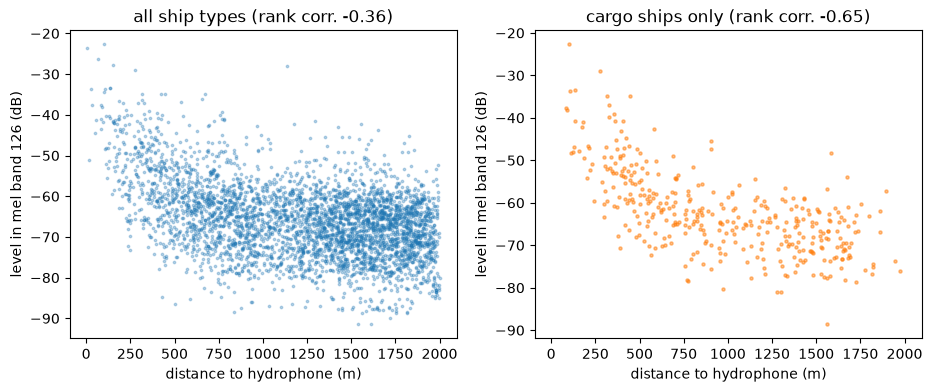

In [7]:
from scipy.stats import spearmanr

s = table[(table.label != "background") & table.mean_distance.notna()].sample(4000, random_state=0).sort_index()
band_db = np.stack([mel[r].astype(np.float32).mean(axis=1) for r in s.index])     # mean level per mel band
best = int(np.argmin([spearmanr(band_db[:, b], s.mean_distance)[0] for b in range(128)]))
cargo = (s.label == "cargo").to_numpy()

fig, ax = plt.subplots(1, 2, figsize=(11, 4), sharex=True)
ax[0].scatter(s.mean_distance, band_db[:, best], s=3, alpha=0.3)
ax[0].set_title(f"all ship types (rank corr. {spearmanr(band_db[:, best], s.mean_distance)[0]:.2f})")
ax[1].scatter(s.mean_distance[cargo], band_db[cargo, best], s=5, alpha=0.5, color="tab:orange")
ax[1].set_title(f"cargo ships only (rank corr. {spearmanr(band_db[cargo, best], s.mean_distance[cargo])[0]:.2f})")
for a in ax: a.set_xlabel("distance to hydrophone (m)"); a.set_ylabel(f"level in mel band {best} (dB)")
plt.show()

Across **all** ship types the link is weak: a big cargo ship 1.5 km away can be as loud as a small boat
300 m away. Within **one** ship type it is strong. So distance can be learned, but only once the model knows
what kind of ship it hears. That's why the distance model starts from the trained class model
(`--init-from`, lesson 09).

## Try it

1. In section 3, change `F.N_FFT` to 1024 in the `torch.stft` call (and the window). What happens to the
   sharpness of the low tonals, and to the timing detail?
2. Pick a `row` of a `background` clip and compare its spectrogram with a ship's.
3. Repeat the section 6 plot for `tug` and `pleasurecraft`. Is the distance relationship as strong for small boats?